# Data Exploration

In [1]:
import torch
import torchvision
from torchvision.datasets import GTSRB

import numpy  as np
import matplotlib.pyplot as plt

from collections import Counter
from pathlib import Path

OSError: [WinError 1114] A dynamic link library (DLL) initialization routine failed. Error loading "C:\Users\prabh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\lib\c10.dll" or one of its dependencies.

In [ ]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data/raw/gtsrb")

train_csv = pd.read_csv(data_dir / "Train.csv")

print(train_csv.shape)
train_csv.head()

(39209, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [ ]:
print(train_csv["ClassId"].nunique())
print(train_csv["ClassId"].value_counts().sort_index())

43
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64


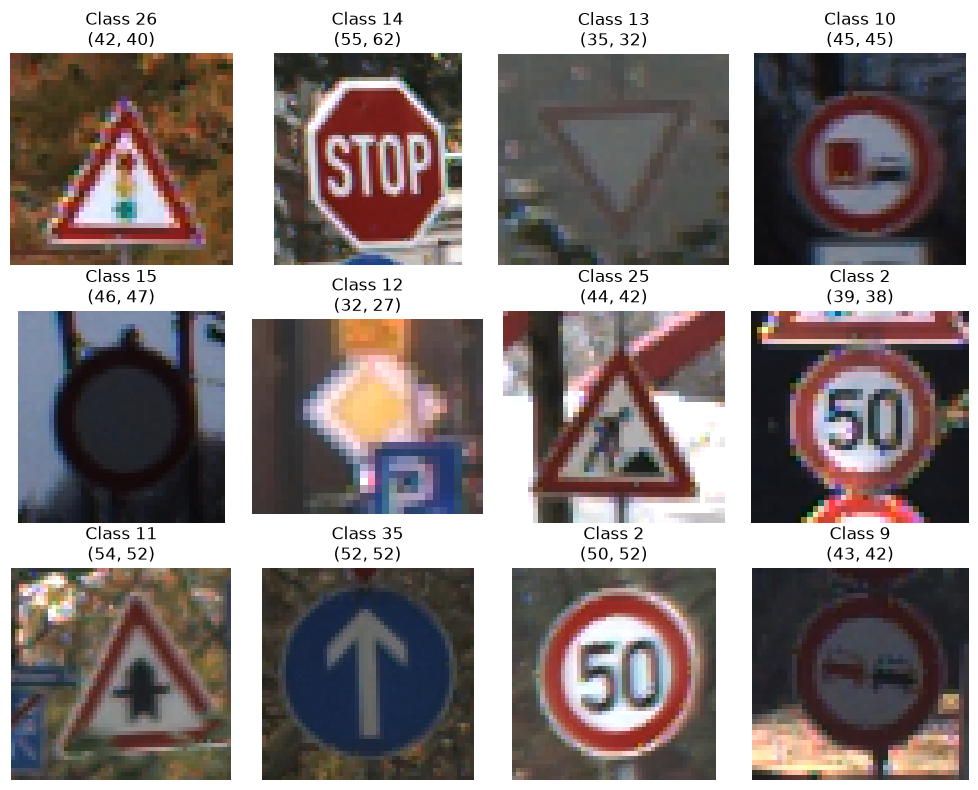

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Randomly choose 12 training examples
samples = train_csv.sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    
    img_path = data_dir / row["Path"]
    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(f"Class {row['ClassId']}\n{img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data/raw/gtsrb")

train_csv = pd.read_csv(data_dir / "Train.csv")
test_csv  = pd.read_csv(data_dir / "Test.csv")

all_df = pd.concat([train_csv, test_csv], ignore_index=True)

print("Total images:", len(all_df))
print("Number of classes:", all_df["ClassId"].nunique())

Total images: 51839
Number of classes: 43


## Test Train Split

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    random_state=42,
    stratify=all_df["ClassId"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["ClassId"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 36287
Validation: 7776
Test: 7776


In [ ]:
n = len(all_df)

print(f"Train: {len(train_df)/n:.2%}")
print(f"Validation: {len(val_df)/n:.2%}")
print(f"Test: {len(test_df)/n:.2%}")

Train: 70.00%
Validation: 15.00%
Test: 15.00%


## Resizing and Padding

In [ ]:
from PIL import Image, ImageOps
from torchvision import transforms

class ResizeAndPad:
    def __init__(self, size = (32,32)):
        self.size = size
    def __call__(self, image):
        return ImageOps.pad(
            image, 
            self.size,
            method = Image.Resampling.BILINEAR,
            color = (0,0,0),
            centering = (0.5, 0.5, 0.5)
        )

In [ ]:
from torch.utils.data import Dataset
class GTSRBDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = self.root_dir / row["Path"]

        image = Image.open(img_path).convert("RGB")
        label = int(row["ClassId"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor()
])


In [ ]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=transform
)

In [ ]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

36287
7776
7776


In [ ]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([64, 3, 32, 32])
Labels: torch.Size([64])


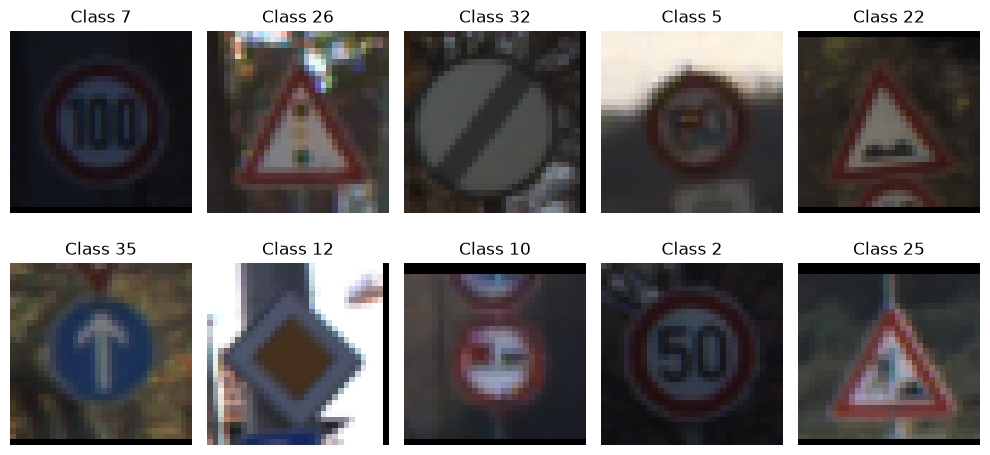

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):
    img = images[i].permute(1, 2, 0)

    ax.imshow(img)
    ax.set_title(f"Class {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Normalizing the Data

In [ ]:
import torch

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
num_pixels = 0

for images, _ in train_loader:
    # images shape: [B, C, H, W]
    channel_sum += images.sum(dim=[0, 2, 3]) #summing accross all 64 images, channel by channel
    channel_sum_sq += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / num_pixels
std = torch.sqrt(channel_sum_sq / num_pixels - mean ** 2)

print("Mean:", mean)
print("Std :", std)

Mean: tensor([0.3219, 0.2955, 0.3048])
Std : tensor([0.2742, 0.2621, 0.2689])


New Transform including the normalization

In [ ]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [ ]:
train_dataset = GTSRBDataset(train_df, data_dir, transform = transform)
val_dataset = GTSRBDataset(val_df,data_dir, transform= transform)
test_dataset = GTSRBDataset(test_df, data_dir, transform = transform)


In [ ]:
train_transform = transforms.Compose([
    ResizeAndPad((32, 32)),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [ ]:
eval_transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [ ]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=train_transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=eval_transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=eval_transform
)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

## CNN Model A

In [ ]:
from torch import nn

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 43)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [ ]:
model_a = LeNet()
print(model_a)

LeNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=43, bias=True)
  (relu): ReLU()
)


In [ ]:
images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = model_a(images)

print("Output:", outputs.shape)

Input: torch.Size([64, 3, 32, 32])
Output: torch.Size([64, 43])


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

Using: cpu


In [ ]:
model_a = model_a.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 20

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model_a.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Remove gradients from previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model_a(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total

    # -------------------------
    # Validation
    # -------------------------
    model_a.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_a(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total

    # Store results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/20 | Train Loss: 1.4423 | Train Acc: 0.5864 | Val Loss: 0.5005 | Val Acc: 0.8569
Epoch  2/20 | Train Loss: 0.3915 | Train Acc: 0.8837 | Val Loss: 0.2593 | Val Acc: 0.9244
Epoch  3/20 | Train Loss: 0.2396 | Train Acc: 0.9293 | Val Loss: 0.1932 | Val Acc: 0.9432
Epoch  4/20 | Train Loss: 0.1722 | Train Acc: 0.9494 | Val Loss: 0.1274 | Val Acc: 0.9666
Epoch  5/20 | Train Loss: 0.1344 | Train Acc: 0.9610 | Val Loss: 0.1067 | Val Acc: 0.9708
Epoch  6/20 | Train Loss: 0.1072 | Train Acc: 0.9689 | Val Loss: 0.1302 | Val Acc: 0.9624
Epoch  7/20 | Train Loss: 0.0974 | Train Acc: 0.9712 | Val Loss: 0.0913 | Val Acc: 0.9761
Epoch  8/20 | Train Loss: 0.0792 | Train Acc: 0.9780 | Val Loss: 0.0742 | Val Acc: 0.9812
Epoch  9/20 | Train Loss: 0.0689 | Train Acc: 0.9786 | Val Loss: 0.0834 | Val Acc: 0.9814
Epoch 10/20 | Train Loss: 0.0639 | Train Acc: 0.9799 | Val Loss: 0.0767 | Val Acc: 0.9814
Epoch 11/20 | Train Loss: 0.0586 | Train Acc: 0.9827 | Val Loss: 0.0639 | Val Acc: 0.9843
Epoch 12/2

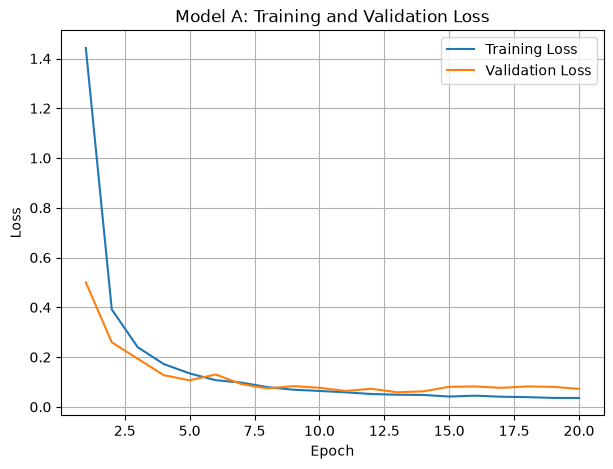

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A: Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

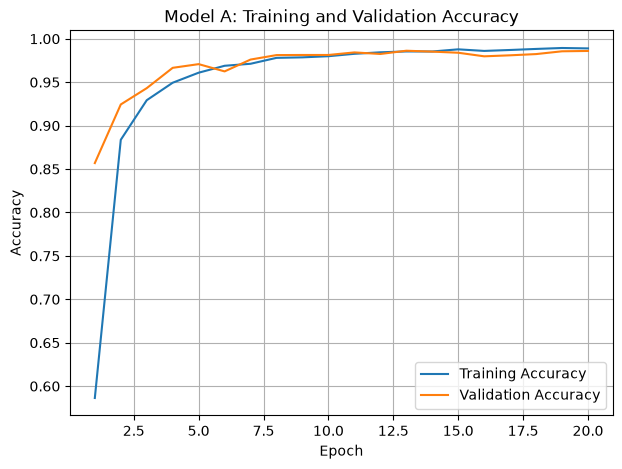

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A: Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

In [ ]:
model_a.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_a(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.0679
Test Accuracy: 0.9870


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

cm = confusion_matrix(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("Weighted Precision:", precision)
print("Weighted Recall:", recall)

Weighted Precision: 0.9872504667349971
Weighted Recall: 0.9870113168724279


In [ ]:
macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("Macro Precision:", macro_precision)
print("Macro Recall:", macro_recall)

Macro Precision: 0.9842575302056985
Macro Recall: 0.9860182956969482


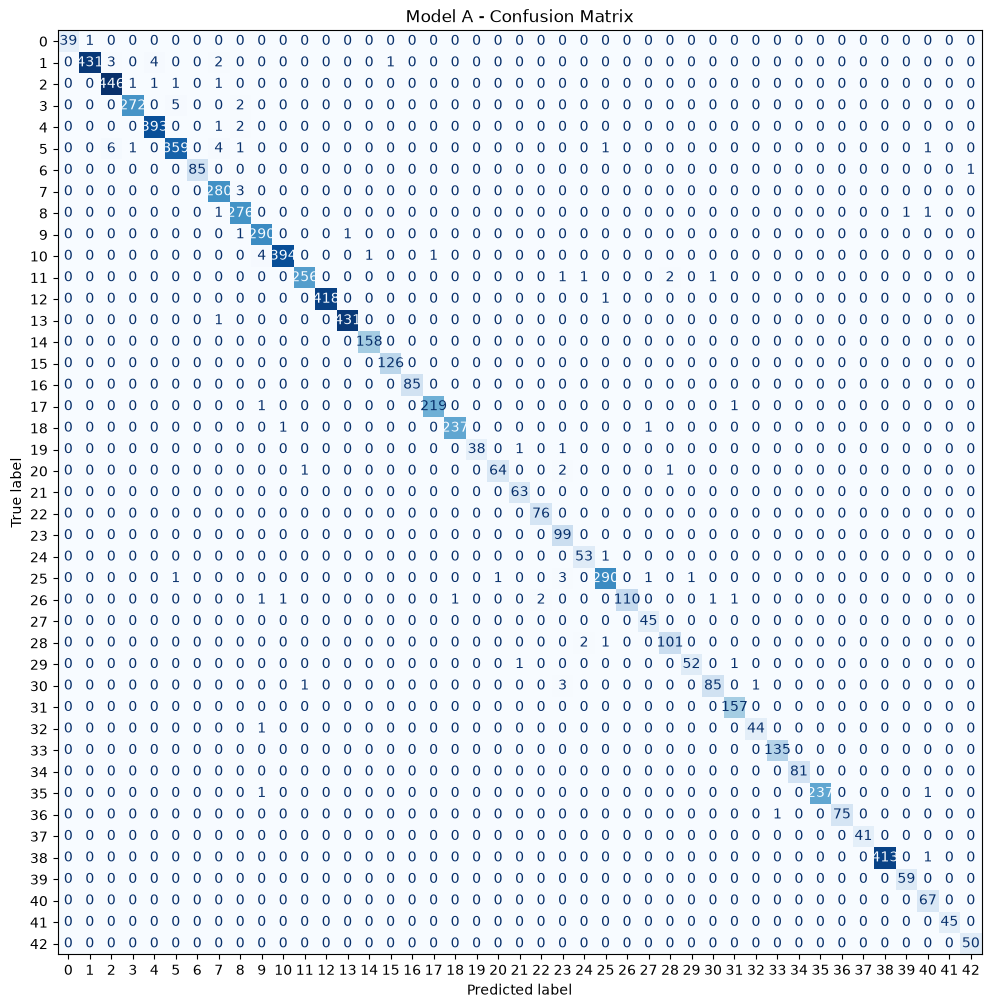

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Model A - Confusion Matrix")
plt.show()

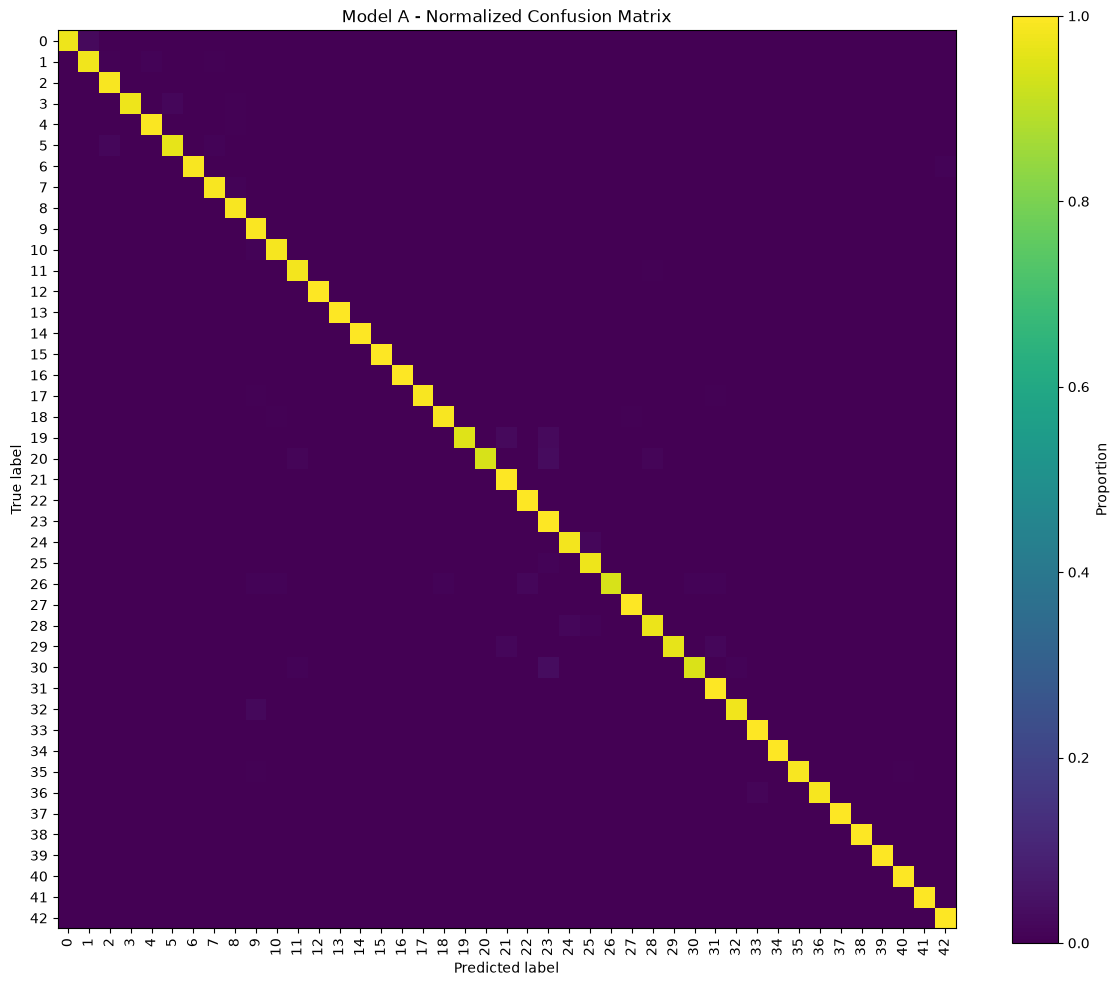

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")
plt.title("Model A - Normalized Confusion Matrix")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

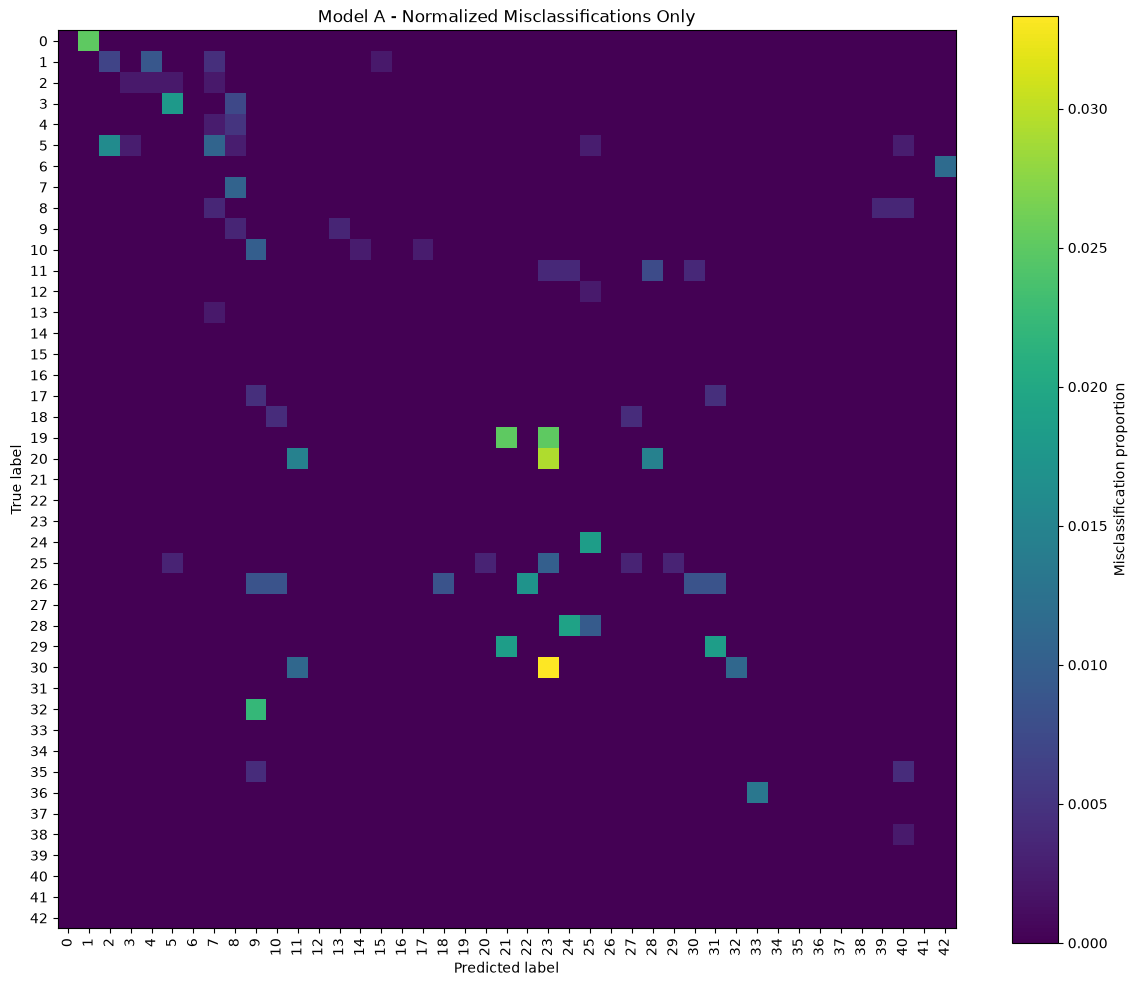

In [ ]:
cm_errors = cm_norm.copy()

# Remove correct predictions
import numpy as np
np.fill_diagonal(cm_errors, 0)

plt.figure(figsize=(12, 10))

plt.imshow(cm_errors, interpolation="nearest")
plt.title("Model A - Normalized Misclassifications Only")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Misclassification proportion")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

cm_errors = cm_norm.copy()
np.fill_diagonal(cm_errors, 0)

# Find the 10 largest off-diagonal entries
flat_indices = np.argsort(cm_errors.ravel())[::-1]

print("Top confusion pairs:")
count = 0

for idx in flat_indices:
    true_class, predicted_class = np.unravel_index(idx, cm_errors.shape)
    value = cm_errors[true_class, predicted_class]

    if value == 0:
        break

    print(
        f"True {true_class:2d} → Predicted {predicted_class:2d}: "
        f"{value * 100:.2f}%"
    )

    count += 1
    if count == 10:
        break

Top confusion pairs:
True 30 → Predicted 23: 3.33%
True 20 → Predicted 23: 2.94%
True  0 → Predicted  1: 2.50%
True 19 → Predicted 23: 2.50%
True 19 → Predicted 21: 2.50%
True 32 → Predicted  9: 2.22%
True 28 → Predicted 24: 1.92%
True 24 → Predicted 25: 1.85%
True 29 → Predicted 21: 1.85%
True 29 → Predicted 31: 1.85%


## CNN Model A v2 

Added another conv layer

In [ ]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            3, 16,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            16, 32,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            32, 64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 43)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

Training

In [ ]:
import torch
import torch.nn as nn
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

model_improved = ImprovedCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_improved.parameters(),
    lr=0.001
)

Using: cpu


In [ ]:
num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_acc = 0.0
best_model_state = None

for epoch in range(num_epochs):

    # =====================================================
    # TRAINING
    # =====================================================
    model_improved.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_improved(images)

        # Loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total


    # =====================================================
    # VALIDATION
    # =====================================================
    model_improved.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_improved(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total


    # =====================================================
    # STORE RESULTS
    # =====================================================
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)


    # Save the best model according to validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model_improved.state_dict())


    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/20 | Train Loss: 1.8420 | Train Acc: 0.4591 | Val Loss: 0.6956 | Val Acc: 0.7836
Epoch  2/20 | Train Loss: 0.4670 | Train Acc: 0.8528 | Val Loss: 0.2475 | Val Acc: 0.9285
Epoch  3/20 | Train Loss: 0.2118 | Train Acc: 0.9350 | Val Loss: 0.1467 | Val Acc: 0.9586
Epoch  4/20 | Train Loss: 0.1355 | Train Acc: 0.9587 | Val Loss: 0.1288 | Val Acc: 0.9633
Epoch  5/20 | Train Loss: 0.0962 | Train Acc: 0.9696 | Val Loss: 0.0727 | Val Acc: 0.9806
Epoch  6/20 | Train Loss: 0.0775 | Train Acc: 0.9761 | Val Loss: 0.0580 | Val Acc: 0.9856
Epoch  7/20 | Train Loss: 0.0632 | Train Acc: 0.9810 | Val Loss: 0.0702 | Val Acc: 0.9802
Epoch  8/20 | Train Loss: 0.0512 | Train Acc: 0.9834 | Val Loss: 0.0493 | Val Acc: 0.9871
Epoch  9/20 | Train Loss: 0.0539 | Train Acc: 0.9829 | Val Loss: 0.0778 | Val Acc: 0.9807
Epoch 10/20 | Train Loss: 0.0413 | Train Acc: 0.9871 | Val Loss: 0.0460 | Val Acc: 0.9882
Epoch 11/20 | Train Loss: 0.0398 | Train Acc: 0.9875 | Val Loss: 0.0645 | Val Acc: 0.9835
Epoch 12/2

Training and Validation Curves

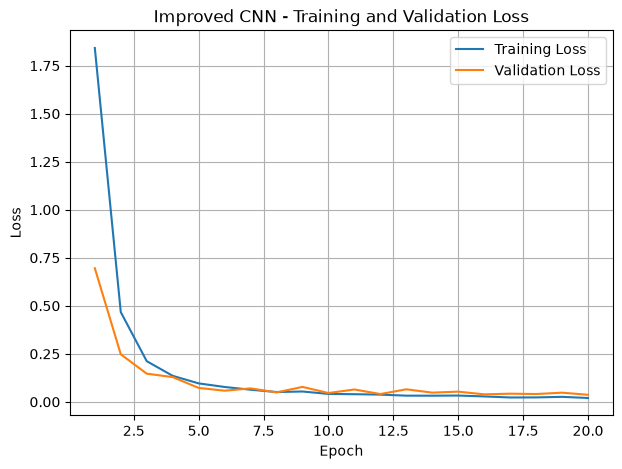

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN - Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

Accuracy

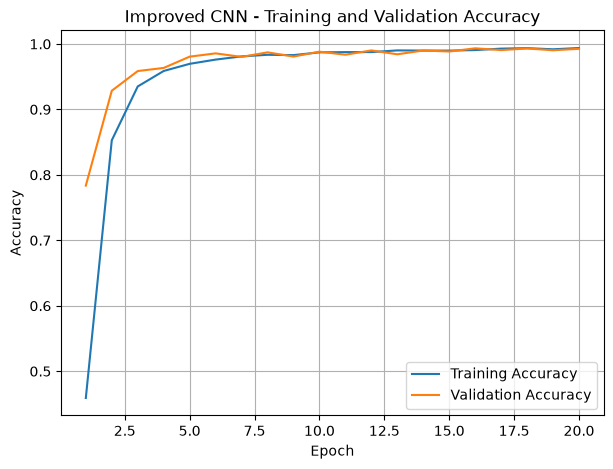

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN - Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

Test Eval

In [ ]:
model_improved.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_improved(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss:     0.0380
Test Accuracy: 0.9923


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

weighted_precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

print()

print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")

Weighted Precision: 0.9923
Weighted Recall:    0.9923
Weighted F1:        0.9923

Macro Precision:    0.9918
Macro Recall:       0.9916
Macro F1:           0.9917


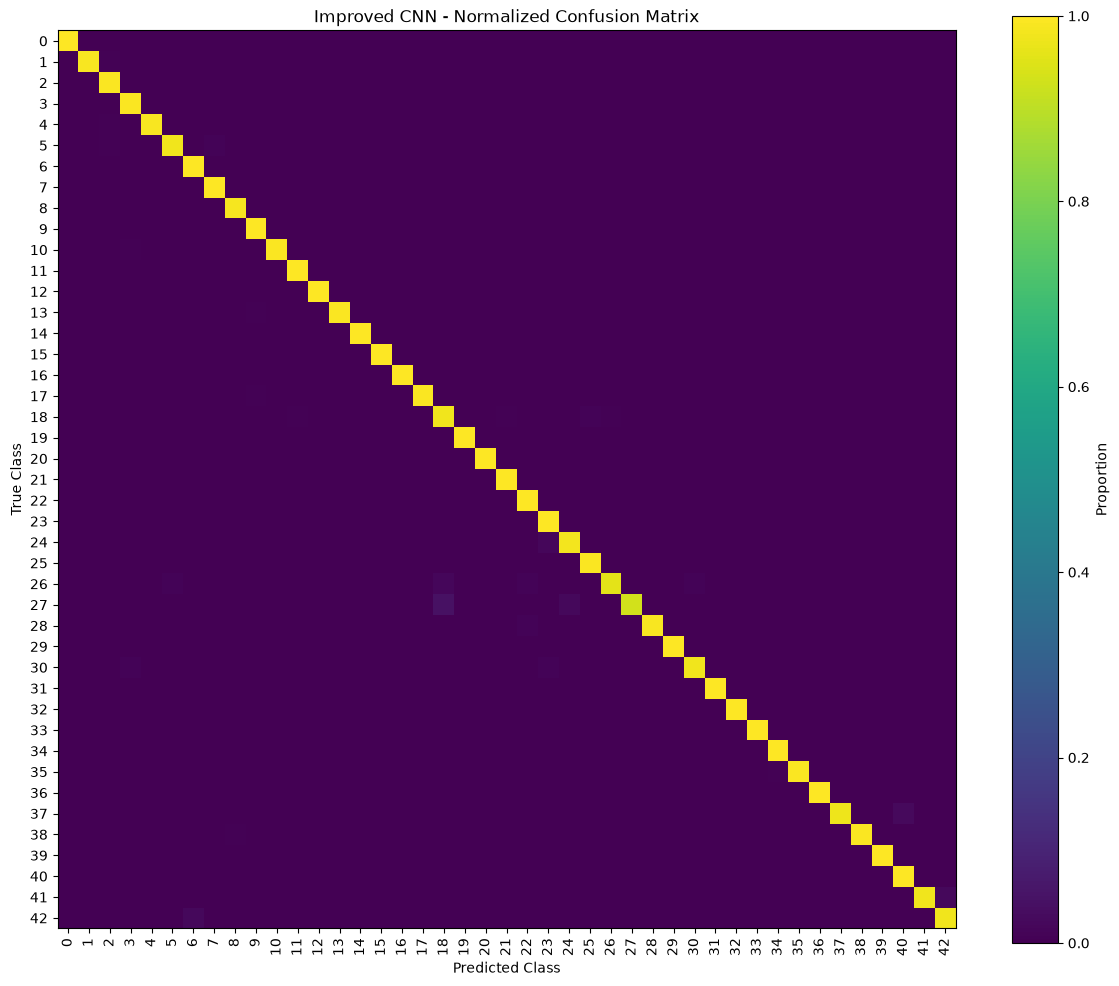

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")

plt.title("Improved CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

In [ ]:
total_params = sum(
    p.numel()
    for p in model_improved.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 160331
